In [21]:
import pandas as pd
import matplotlib.pyplot as plt

# Jalankan notebook dari folder proyek; file cleaned berada di folder data/cleaned.
df = pd.read_csv(
    '../data/cleaned/Sample-Superstore-Cleaned.csv',
    dtype={'postal_code': 'string'},
    parse_dates=['order_date', 'ship_date']
)

print('Ukuran dataset:', df.shape)
display(df.head())
display(df.dtypes)


Ukuran dataset: (9993, 20)


,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,city,state,postal_code,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit,shipping_duration
0,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,3
1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,3
2,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,4
3,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,7
4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,7


order_id                     object
order_date           datetime64[ns]
ship_date            datetime64[ns]
ship_mode                    object
customer_id                  object
customer_name                object
segment                      object
city                         object
state                        object
postal_code          string[python]
region                       object
product_id                   object
category                     object
sub_category                 object
product_name                 object
sales                       float64
quantity                      int64
discount                    float64
profit                      float64
shipping_duration             int64
dtype: object

In [22]:
total_sales = df['sales'].sum()
total_profit = df['profit'].sum()
profit_margin = (total_profit / total_sales) * 100

total_orders = df['order_id'].nunique()
total_customers = df['customer_id'].nunique()
avg_order_value = total_sales / total_orders

margin_rata2_baris = (df['profit'] / df['sales']).mean() * 100
print(f'Margin total: {profit_margin:.2f}% | Rata-rata margin per baris: {margin_rata2_baris:.2f}%')

Margin total: 12.47% | Rata-rata margin per baris: 12.03%


In [23]:
kpi = pd.DataFrame({
    'KPI': [
        'Total Sales',
        'Total Profit',
        'Profit Margin',
        'Total Orders',
        'Total Customers',
        'Average Order Value'
    ],
    'Value': [
        total_sales,
        total_profit,
        profit_margin,
        total_orders,
        total_customers,
        avg_order_value
    ]
})

display(kpi.round(2))

,KPI,Value
0,Total Sales,2296919.49
1,Total Profit,286409.08
2,Profit Margin,12.47
3,Total Orders,5009.00
4,Total Customers,793.00
5,Average Order Value,458.56


*Berdasarkan perhitungan KPI dasar, total penjualan mencapai 2,296,919 dengan total profit sebesar 286,409 Profit margin sebesar 12%, yang berarti perusahaan memperoleh profit sekitar 12% dari total nilai penjualannya. Dataset mencatat 5009 pesanan unik dari 793 pelanggan, dengan rata-rata nilai pesanan sebesar 458.*

In [24]:
df['year'] = df['order_date'].dt.year
df['month'] = df['order_date'].dt.month
df['quarter'] = df['order_date'].dt.quarter
df['quarter_name'] = 'Q' + df['quarter'].astype(str)
df['year_month'] = df['order_date'].dt.to_period('M')

display(
    df[['order_date', 'year', 'quarter_name', 'month', 'year_month']].head()
)

,order_date,year,quarter_name,month,year_month
0,2016-11-08,2016,Q4,11,2016-11
1,2016-11-08,2016,Q4,11,2016-11
2,2016-06-12,2016,Q2,6,2016-06
3,2015-10-11,2015,Q4,10,2015-10
4,2015-10-11,2015,Q4,10,2015-10


**Visualisasi Trend Tahunan**

In [25]:
yearly_trend = df.groupby('year').agg(
    total_sales=('sales', 'sum'),
    total_profit=('profit', 'sum'),
    orders=('order_id', 'nunique')
).reset_index()
yearly_trend['margin'] = yearly_trend['total_profit'] / yearly_trend['total_sales']
yearly_trend['aov'] = yearly_trend['total_sales'] / yearly_trend['orders']

In [26]:
yearly_trend['sales_growth'] = yearly_trend['total_sales'].pct_change() * 100
yearly_trend['profit_growth'] = yearly_trend['total_profit'].pct_change() * 100
yearly_trend['margin_%'] = yearly_trend['total_profit'] / yearly_trend['total_sales'] * 100

display(yearly_trend.round(2))

,year,total_sales,total_profit,orders,margin,aov,sales_growth,profit_growth,margin_%
0,2014,483966.13,49556.03,969,0.10,499.45,NaN,NaN,10.24
1,2015,470532.51,61618.60,1038,0.13,453.31,-2.78,24.34,13.10
2,2016,609205.60,81795.17,1315,0.13,463.27,29.47,32.74,13.43
3,2017,733215.26,93439.27,1687,0.13,434.63,20.36,14.24,12.74


*Sales tumbuh 51,5% (483.966 → 733.215) dan profit tumbuh 88,5% (49.556 → 93.439) dari 2014 ke 2017. Namun di 2017 profit tumbuh 14% sementara sales tumbuh 20%, dan margin turun dari 13,4% ke 12,7%. Pesanan naik 74% tetapi rata-rata nilai per pesanan turun 13% (499 → 435), jadi pertumbuhan sales didorong oleh jumlah pesanan, bukan nilai tiap pesanan.*

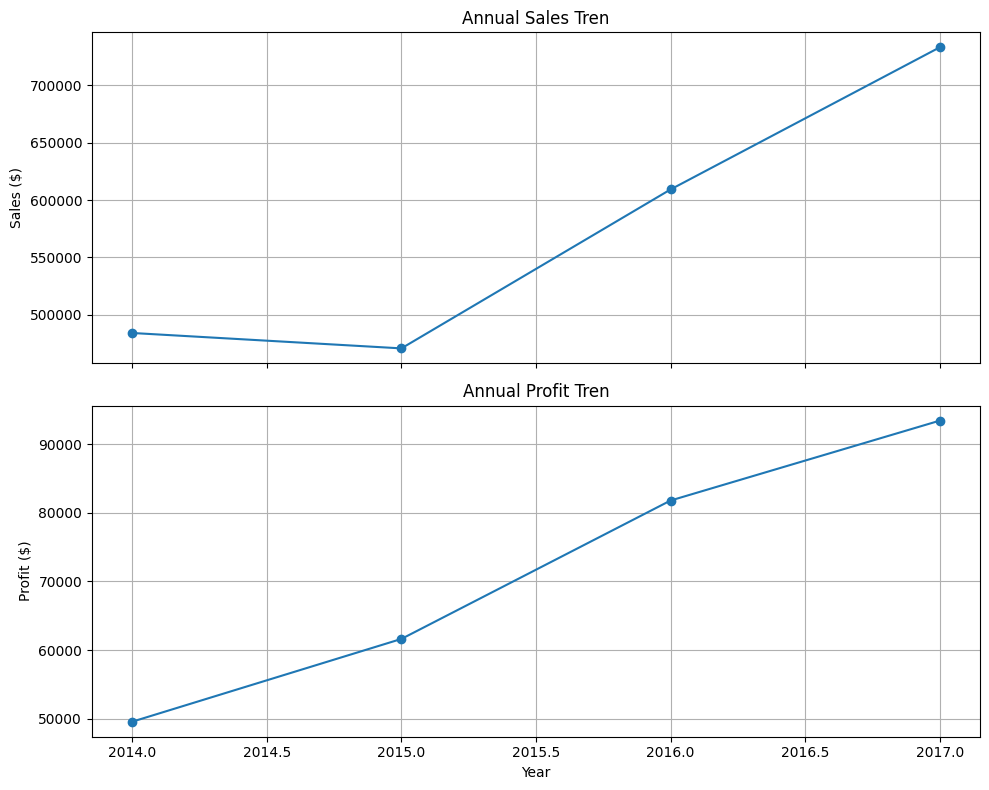

In [27]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

axes[0].plot(yearly_trend['year'], yearly_trend['total_sales'], marker='o')
axes[0].set_title('Annual Sales Tren')
axes[0].set_ylabel('Sales ($)')
axes[0].grid(True)

axes[1].plot(yearly_trend['year'], yearly_trend['total_profit'], marker='o')
axes[1].set_title('Annual Profit Tren')
axes[1].set_ylabel('Profit ($)')
axes[1].set_xlabel('Year')
axes[1].grid(True)

plt.tight_layout()
plt.show()

*Pada tahun 2017, sales tumbuh sebesar 20%, sedangkan profit tumbuh sebesar 14%. Hal ini menunjukkan bahwa profit tumbuh lebih lambat dibandingkan sales pada periode tersebut.*


**VIsualisasi Trend Kuartal**

In [28]:
quarterly_trend = df.groupby(['year', 'quarter']).agg(
    total_sales=('sales', 'sum'),
    total_profit=('profit', 'sum')
).reset_index()

quarterly_trend['quarter_name'] = 'Q' + quarterly_trend['quarter'].astype(str)
quarterly_trend['year_quarter'] = (
    quarterly_trend['year'].astype(str) + '-' + quarterly_trend['quarter_name']
)

display(quarterly_trend.round(2))

,year,quarter,total_sales,total_profit,quarter_name,year_quarter
0,2014,1,74447.80,3811.23,Q1,2014-Q1
1,2014,2,86257.39,11216.13,Q2,2014-Q2
2,2014,3,143633.21,12804.72,Q3,2014-Q3
3,2014,4,179627.73,21723.95,Q4,2014-Q4
4,2015,1,68851.74,9264.94,Q1,2015-Q1
5,2015,2,89124.19,12190.92,Q2,2015-Q2
6,2015,3,130259.58,16853.62,Q3,2015-Q3
7,2015,4,182297.01,23309.12,Q4,2015-Q4
8,2016,1,93237.18,11441.37,Q1,2016-Q1
9,2016,2,136082.30,16390.34,Q2,2016-Q2


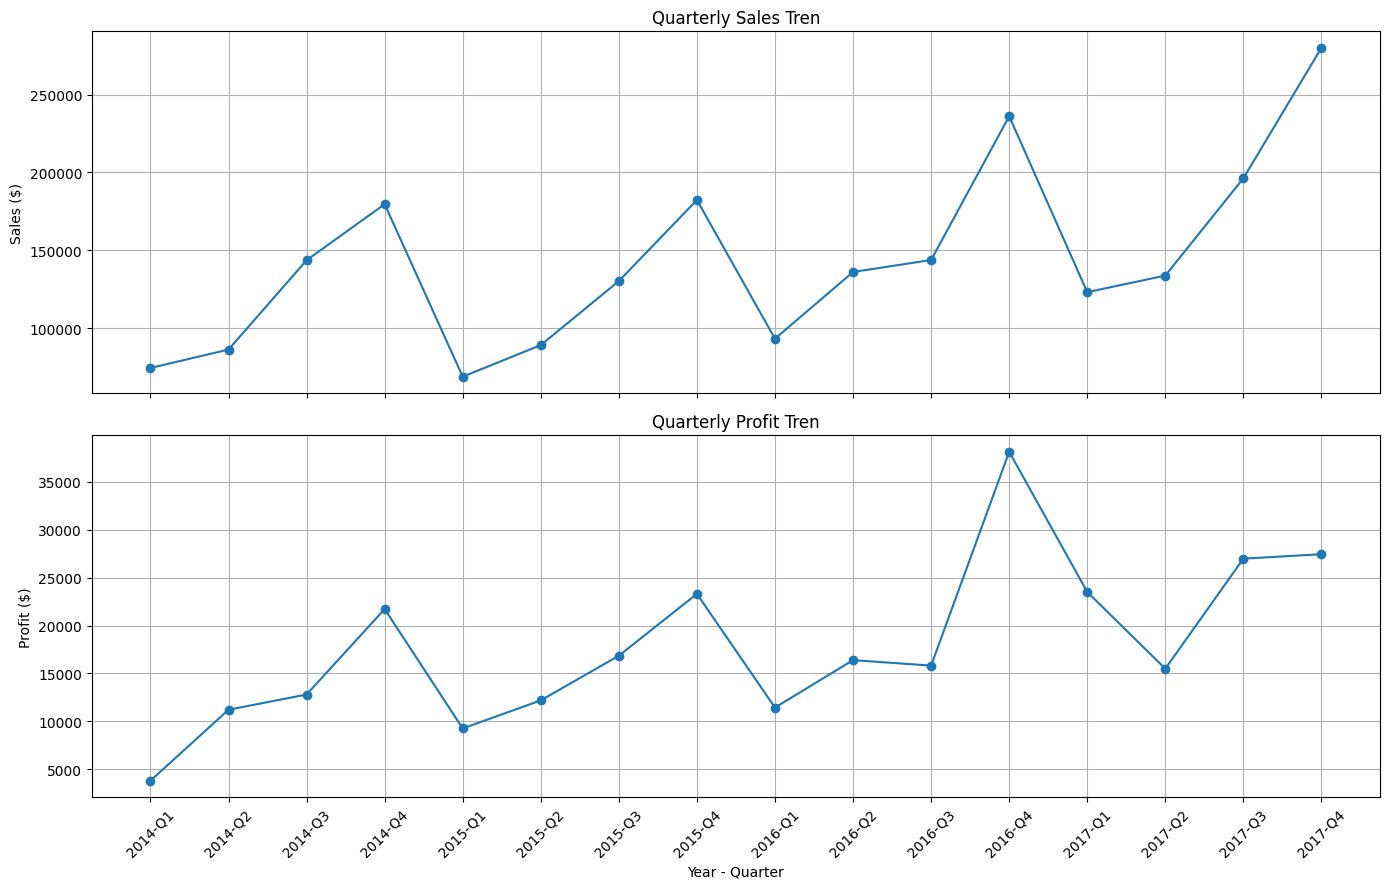

In [29]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

axes[0].plot(quarterly_trend['year_quarter'], quarterly_trend['total_sales'], marker='o')
axes[0].set_title('Quarterly Sales Tren')
axes[0].set_ylabel('Sales ($)')
axes[0].grid(True)

axes[1].plot(quarterly_trend['year_quarter'], quarterly_trend['total_profit'], marker='o')
axes[1].set_title('Quarterly Profit Tren')
axes[1].set_ylabel('Profit ($)')
axes[1].set_xlabel('Year - Quarter')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [30]:
quarterly_seasonality = quarterly_trend.groupby('quarter').agg(
    avg_sales=('total_sales', 'mean'),
    avg_profit=('total_profit', 'mean')
).reset_index()

quarterly_seasonality['quarter_name'] = 'Q' + quarterly_seasonality['quarter'].astype(str)

display(quarterly_seasonality.round(2))

,quarter,avg_sales,avg_profit,quarter_name
0,1,89920.39,12005.94,Q1
1,2,111307.06,13824.15,Q2
2,3,153483.03,18116.77,Q3
3,4,219519.39,27655.41,Q4


In [31]:
quarterly_trend['margin_%'] = quarterly_trend['total_profit'] / quarterly_trend['total_sales'] * 100
display(quarterly_trend[['year_quarter', 'total_sales', 'total_profit', 'margin_%']].round(2))

,year_quarter,total_sales,total_profit,margin_%
0,2014-Q1,74447.80,3811.23,5.12
1,2014-Q2,86257.39,11216.13,13.00
2,2014-Q3,143633.21,12804.72,8.91
3,2014-Q4,179627.73,21723.95,12.09
4,2015-Q1,68851.74,9264.94,13.46
5,2015-Q2,89124.19,12190.92,13.68
6,2015-Q3,130259.58,16853.62,12.94
7,2015-Q4,182297.01,23309.12,12.79
8,2016-Q1,93237.18,11441.37,12.27
9,2016-Q2,136082.30,16390.34,12.04


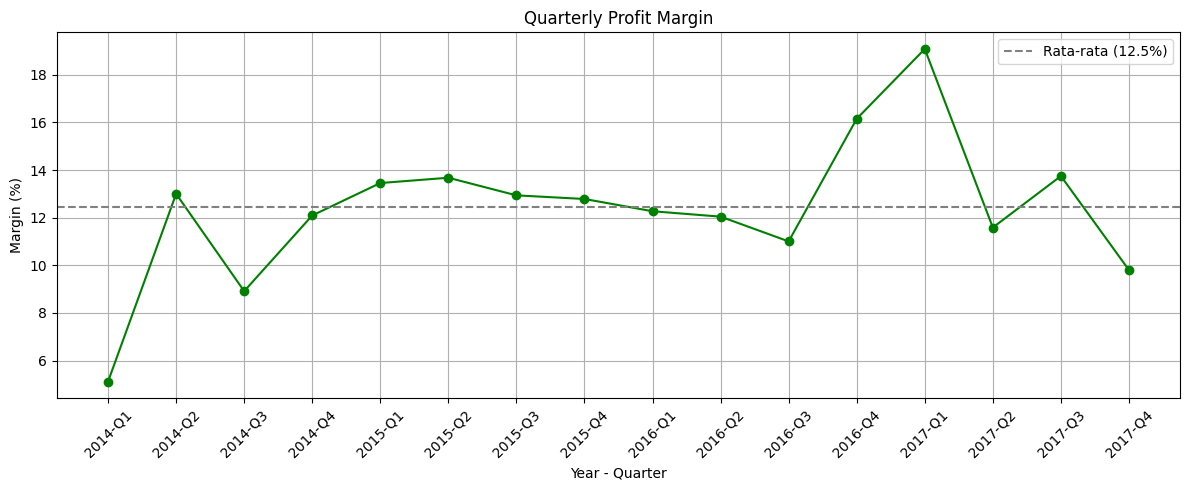

In [32]:
plt.figure(figsize=(12, 5))
plt.plot(quarterly_trend['year_quarter'], quarterly_trend['margin_%'], marker='o', color='green')
plt.axhline(profit_margin, linestyle='--', color='gray', label=f'Rata-rata ({profit_margin:.1f}%)')
plt.title('Quarterly Profit Margin')
plt.xlabel('Year - Quarter'); plt.ylabel('Margin (%)')
plt.xticks(rotation=45); plt.legend(); plt.grid(True)
plt.tight_layout(); plt.show()

*Kuartal 4 adalah kuartal dengan sales tertinggi di keempat tahun (rata-rata 219.519), dan Kuartal 1 yang terendah (89.920). Pada Q4 2017, sales naik ±18,6% dibanding Q4 2016, tetapi profit turun ±28% dan margin jatuh dari ±16,2% ke ±9,8%.*

**Visualisasi Trend Bulanan**

In [33]:
monthly_trend = df.groupby('year_month').agg(
    total_sales=('sales', 'sum'),
    total_profit=('profit', 'sum')
).reset_index()

monthly_trend['year_month'] = monthly_trend['year_month'].astype(str)

In [34]:
monthly_trend[monthly_trend['total_profit'] < 0]     # bulan dengan profit negatif
monthly_trend.loc[monthly_trend['total_profit'].idxmax()]   # bulan profit tertinggi

year_month         2016-12
total_sales      96999.043
total_profit    17885.3093
Name: 35, dtype: object

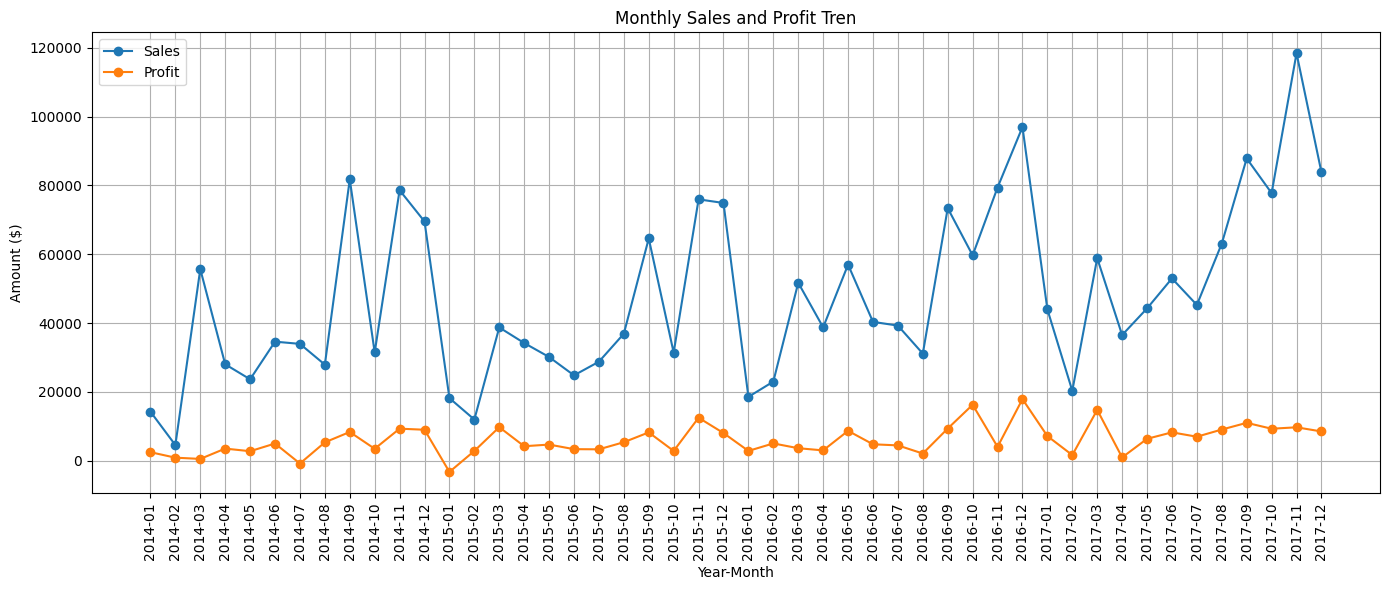

In [35]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_trend['year_month'],
    monthly_trend['total_sales'],
    label='Sales',
    marker='o'
)

plt.plot(
    monthly_trend['year_month'],
    monthly_trend['total_profit'],
    label='Profit',
    marker='o'
)

plt.title('Monthly Sales and Profit Tren')
plt.xlabel('Year-Month')
plt.ylabel('Amount ($)')
plt.xticks(rotation=90)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [36]:
monthly_seasonality = df.groupby(['year', 'month']).agg(
    total_sales=('sales', 'sum'),
    total_profit=('profit', 'sum')
).reset_index()

seasonality = monthly_seasonality.groupby('month').agg(
    avg_sales=('total_sales', 'mean'),
    avg_profit=('total_profit', 'mean')
).reset_index()

month_names = {
    1: 'January', 2: 'February', 3: 'March',
    4: 'April', 5: 'May', 6: 'June',
    7: 'July', 8: 'August', 9: 'September',
    10: 'October', 11: 'November', 12: 'December'
}

seasonality['month_name'] = seasonality['month'].map(month_names)

display(seasonality.round(2))

,month,avg_sales,avg_profit,month_name
0,1,23731.21,2283.61,January
1,2,14937.81,2573.65,February
2,3,51251.37,7148.67,March
3,4,34370.19,2899.87,April
4,5,38757.20,5602.83,May
5,6,38179.67,5321.45,June
6,7,36809.52,3458.17,July
7,8,39761.02,5444.23,August
8,9,76912.49,9214.37,September
9,10,50080.75,7946.01,October


,month_name,avg_sales,avg_profit,avg_margin_%
0,January,23731.21,2283.61,9.62
1,February,14937.81,2573.65,17.23
2,March,51251.37,7148.67,13.95
3,April,34370.19,2899.87,8.44
4,May,38757.20,5602.83,14.46
5,June,38179.67,5321.45,13.94
6,July,36809.52,3458.17,9.39
7,August,39761.02,5444.23,13.69
8,September,76912.49,9214.37,11.98
9,October,50080.75,7946.01,15.87


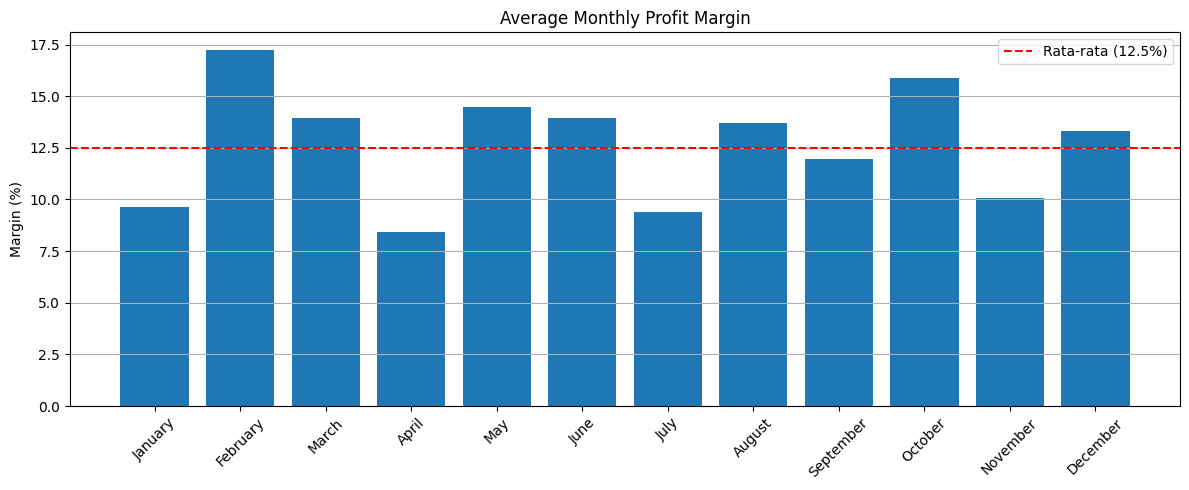

In [37]:
seasonality['avg_margin_%'] = seasonality['avg_profit'] / seasonality['avg_sales'] * 100
display(seasonality[['month_name', 'avg_sales', 'avg_profit', 'avg_margin_%']].round(2))

plt.figure(figsize=(12, 5))
plt.bar(seasonality['month_name'], seasonality['avg_margin_%'])
plt.axhline(profit_margin, linestyle='--', color='red', label=f'Rata-rata ({profit_margin:.1f}%)')
plt.title('Average Monthly Profit Margin'); plt.ylabel('Margin (%)')
plt.xticks(rotation=45); plt.legend(); plt.grid(axis='y')
plt.tight_layout(); plt.show()

In [38]:
highest_sales_month = seasonality.loc[seasonality['avg_sales'].idxmax()]
lowest_sales_month = seasonality.loc[seasonality['avg_sales'].idxmin()]
highest_profit_month = seasonality.loc[seasonality['avg_profit'].idxmax()]
lowest_profit_month = seasonality.loc[seasonality['avg_profit'].idxmin()]

print('Sales tertinggi:', highest_sales_month['month_name'], round(highest_sales_month['avg_sales'], 2))
print('Sales terendah:', lowest_sales_month['month_name'], round(lowest_sales_month['avg_sales'], 2))
print('Profit tertinggi:', highest_profit_month['month_name'], round(highest_profit_month['avg_profit'], 2))
print('Profit terendah:', lowest_profit_month['month_name'], round(lowest_profit_month['avg_profit'], 2))

Sales tertinggi: November 88115.27
Sales terendah: February 14937.81
Profit tertinggi: December 10842.3
Profit terendah: January 2283.61


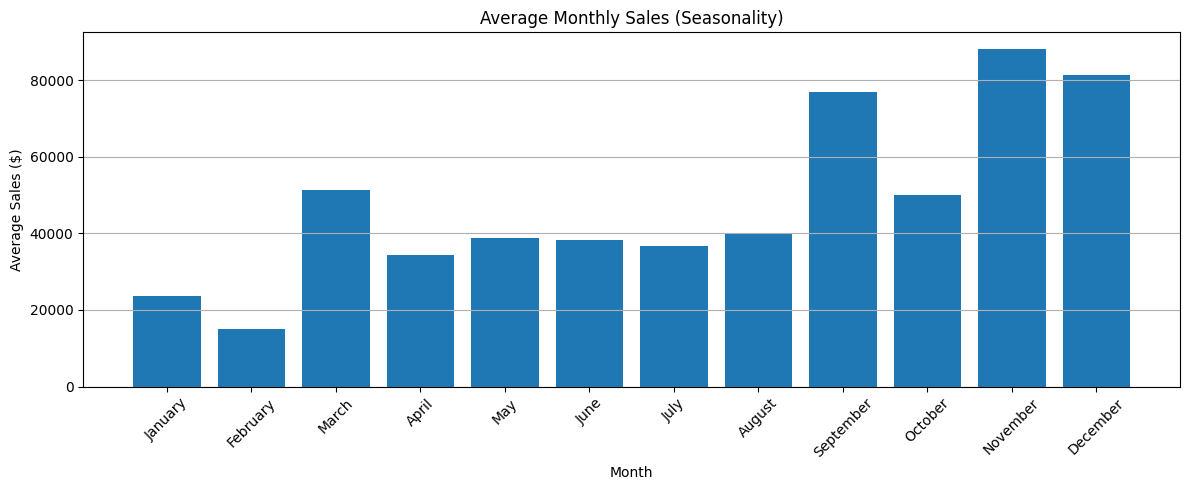

In [39]:
plt.figure(figsize=(12, 5))

plt.bar(seasonality['month_name'], seasonality['avg_sales'])

plt.title('Average Monthly Sales (Seasonality)')
plt.xlabel('Month')
plt.ylabel('Average Sales ($)')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

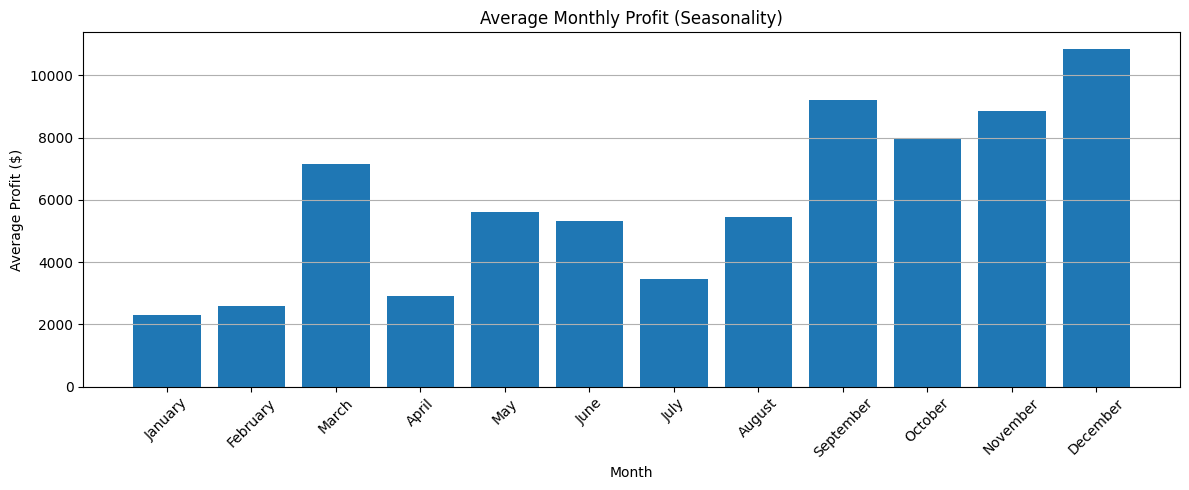

In [40]:
plt.figure(figsize=(12, 5))

plt.bar(seasonality['month_name'], seasonality['avg_profit'])

plt.title('Average Monthly Profit (Seasonality)')
plt.xlabel('Month')
plt.ylabel('Average Profit ($)')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

*Sales rata-rata tertinggi di November (88.115) dan terendah di Februari (14.938). Profit rata-rata tertinggi di Desember (10.842) dan terendah di Januari (2.284). September, November, dan Desember konsisten menjadi bulan ramai.*